=== 三個時段之程序筆數 ===
proc_group                           kernel  sshd(pam_unix)  ftpd  \
period                                                              
Normal Baseline\n(Other 245d)          1991            4727  3345   
Peak Cluster\n(11-20 to 12-06, 17d)   11162             261    85   
Single-Day Spike\n(01-26, 1d)           517               8    23   

proc_group                           su(pam_unix)  udev  Others  
period                                                           
Normal Baseline\n(Other 245d)                 868   358    1658  
Peak Cluster\n(11-20 to 12-06, 17d)            70    61     185  
Single-Day Spike\n(01-26, 1d)                   6    65     159  

=== 三個時段之程序占比 (%) ===
proc_group                           kernel  sshd(pam_unix)   ftpd  \
period                                                               
Normal Baseline\n(Other 245d)         15.38           36.51  25.84   
Peak Cluster\n(11-20 to 12-06, 17d)   94.40            2.21   0.72   
Sin

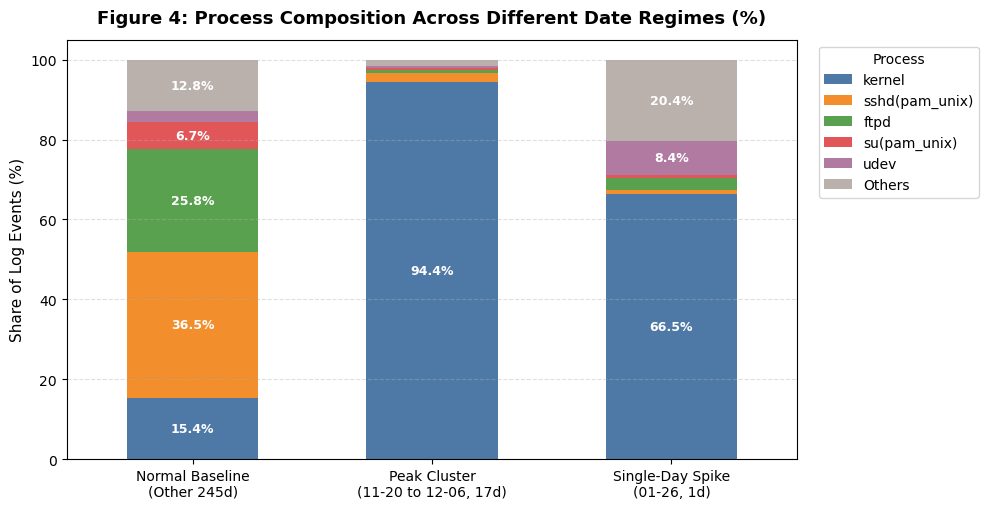

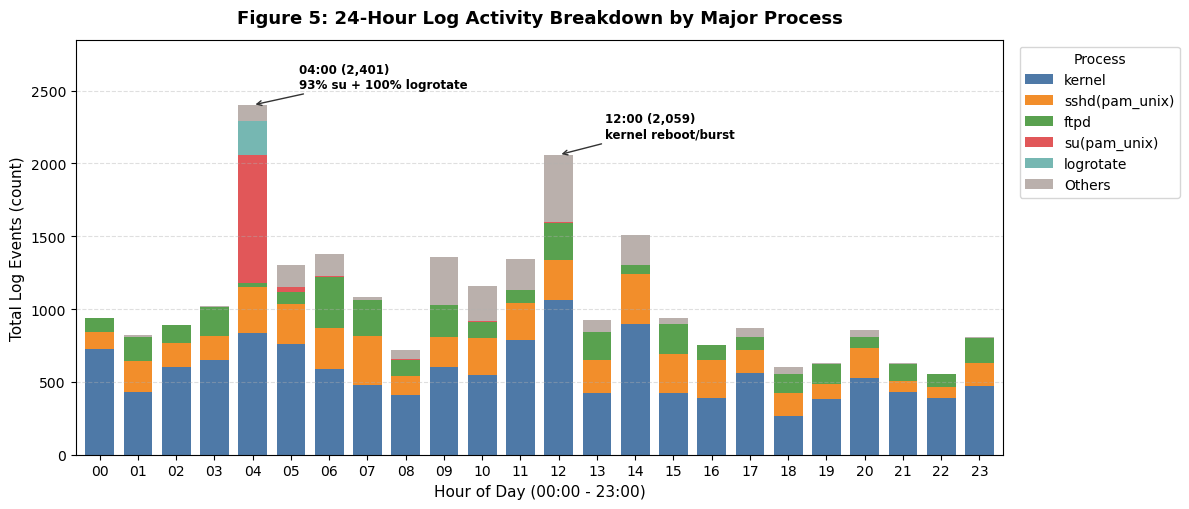


=== 04:00 維護程序集中度 ===
su(pam_unix): 880/944 (93.22%) 發生在 04:00
logrotate: 231/231 (100.00%) 發生在 04:00

11/20~12/06 高峰期總計 11824 筆，其中 OOM 訊息占 9510 筆 (80.43%)


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 讀取 parsed_logs.csv（與本檔案同在 linux_analysis/ 資料夾內）
df = pd.read_csv('parsed_logs.csv')

# 2. 解析日期（月-日）與小時，並建立真實時序（6月~12月 -> 隔年1月~2月）
month_map = {
    'Jan': '01', 'Feb': '02', 'Mar': '03', 'Apr': '04',
    'May': '05', 'Jun': '06', 'Jul': '07', 'Aug': '08',
    'Sep': '09', 'Oct': '10', 'Nov': '11', 'Dec': '12'
}
parts = df['timestamp'].str.split(expand=True)
df['month_num'] = parts[0].map(month_map)
df['day_num'] = parts[1].str.zfill(2)
df['date_md'] = df['month_num'] + '-' + df['day_num']
df['hour'] = parts[2].str.slice(0, 2).astype(int)
df['sort_m'] = df['month_num'].astype(int).apply(lambda m: m if m >= 6 else m + 12)
df['date_sort'] = df['sort_m'] * 100 + df['day_num'].astype(int)

# 3. 切分三個日期區間：平常日 vs. 11/20~12/06 高峰群聚 vs. 01/26 單日尖峰
def classify_period(row):
    if 1120 <= row['date_sort'] <= 1206:
        return 'Peak Cluster\n(11-20 to 12-06, 17d)'
    elif row['date_md'] == '01-26':
        return 'Single-Day Spike\n(01-26, 1d)'
    else:
        return 'Normal Baseline\n(Other 245d)'

df['period'] = df.apply(classify_period, axis=1)
period_order = [
    'Normal Baseline\n(Other 245d)',
    'Peak Cluster\n(11-20 to 12-06, 17d)',
    'Single-Day Spike\n(01-26, 1d)'
]

# 4. 繪製 Figure 4：三個時段的程序組成比例比較圖（100% 堆疊長條圖）
proc_cols = ['kernel', 'sshd(pam_unix)', 'ftpd', 'su(pam_unix)', 'udev', 'Others']
df['proc_group'] = df['process'].where(df['process'].isin(proc_cols[:-1]), 'Others')
ct_period = pd.crosstab(df['period'], df['proc_group']).reindex(period_order)[proc_cols]
ct_pct = ct_period.div(ct_period.sum(axis=1), axis=0) * 100

print('=== 三個時段之程序筆數 ===')
print(ct_period)
print('\n=== 三個時段之程序占比 (%) ===')
print(ct_pct.round(2))

colors4 = ['#4E79A7', '#F28E2B', '#59A14F', '#E15759', '#B07AA1', '#BAB0AC']
fig, ax = plt.subplots(figsize=(10, 5.2))
ct_pct.plot(kind='bar', stacked=True, color=colors4, ax=ax, width=0.55)
ax.set_title('Figure 4: Process Composition Across Different Date Regimes (%)', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Share of Log Events (%)', fontsize=11)
ax.set_xlabel('')
ax.set_ylim(0, 105)
plt.xticks(rotation=0, fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(title='Process', bbox_to_anchor=(1.02, 1), loc='upper left')

for i, idx in enumerate(ct_pct.index):
    cum = 0
    for col in proc_cols:
        val = ct_pct.loc[idx, col]
        if val >= 6.0:
            ax.text(i, cum + val / 2, f'{val:.1f}%', ha='center', va='center',
                    color='white', fontweight='bold', fontsize=9)
        cum += val

plt.tight_layout()
plt.savefig('m1_fig4_period_process_comparison.png', dpi=300)
plt.show()

# 5. 繪製 Figure 5：24 小時各主要程序堆疊分布圖
hourly_cols = ['kernel', 'sshd(pam_unix)', 'ftpd', 'su(pam_unix)', 'logrotate', 'Others']
df['proc_hourly'] = df['process'].where(df['process'].isin(hourly_cols[:-1]), 'Others')
ct_hour = pd.crosstab(df['hour'], df['proc_hourly']).reindex(range(24), fill_value=0)[hourly_cols]

colors5 = ['#4E79A7', '#F28E2B', '#59A14F', '#E15759', '#76B7B2', '#BAB0AC']
fig, ax = plt.subplots(figsize=(12, 5.2))
ct_hour.plot(kind='bar', stacked=True, color=colors5, ax=ax, width=0.75)
ax.set_title('Figure 5: 24-Hour Log Activity Breakdown by Major Process', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Hour of Day (00:00 - 23:00)', fontsize=11)
ax.set_ylabel('Total Log Events (count)', fontsize=11)
ax.set_xticklabels([f'{h:02d}' for h in range(24)], rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(title='Process', bbox_to_anchor=(1.01, 1), loc='upper left')

for h, note in [(4, '04:00 (2,401)\n93% su + 100% logrotate'), (12, '12:00 (2,059)\nkernel reboot/burst')]:
    tot = ct_hour.loc[h].sum()
    ax.annotate(note, xy=(h, tot), xytext=(h + 1.2, tot + 120),
                fontsize=8.5, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='#333333', lw=1))

ax.set_ylim(0, 2850)
plt.tight_layout()
plt.savefig('m1_fig5_hourly_process_stacked.png', dpi=300)
plt.show()

# 6. 關鍵數據驗證摘要
print('\n=== 04:00 維護程序集中度 ===')
for p in ['su(pam_unix)', 'logrotate']:
    tot = (df['process'] == p).sum()
    h4 = ((df['process'] == p) & (df['hour'] == 4)).sum()
    print(f'{p}: {h4}/{tot} ({h4/tot*100:.2f}%) 發生在 04:00')

pk = df[df['date_sort'].between(1120, 1206)]
oom = pk['message'].fillna('').str.contains('Out of Memory', case=False).sum()
print(f'\n11/20~12/06 高峰期總計 {len(pk)} 筆，其中 OOM 訊息占 {oom} 筆 ({oom/len(pk)*100:.2f}%)')

# Week 3 進階分析：程序 × 時間分組比較、作業系統詮釋與資料限制（成員 1）

* **負責人**：成員 1（姜羽芯 / 1140352）
* **資料來源**：[Loghub Linux 系統日誌](https://github.com/logpai/loghub/tree/master/Linux)（`linux_analysis/parsed_logs.csv`，共 **25,549** 筆、單一主機 `combo`）

## 1. 條件／分組比較（Compare Conditions / Groups）

### 比較一：三種日期狀態之程序組成差異（對照 Figure 4）
將 263 天依 Week 2 發現的時序特徵切分為三組，可發現不同高峰背後的程序結構截然不同：

| 日期分組 | 天數 | 總筆數 | 日均筆數 | `kernel` | `sshd(pam_unix)` | `ftpd` | `su(pam_unix)` | `udev` | `Others` |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 平常日基準（其餘 245 天） | 245 | 12,947 | 52.8 | 15.38% | **36.51%** | **25.84%** | 6.70% | 2.77% | 12.81% |
| 高峰群聚期（`11-20` ～ `12-06`） | 17 | 11,824 | 695.5 | **94.40%** | 2.21% | 0.72% | 0.59% | 0.52% | 1.56% |
| 單日尖峰（`01-26`） | 1 | 778 | 778.0 | **66.45%** | 1.03% | 2.96% | 0.77% | **8.35%** | **20.44%** |

* **平常日（日均 52.8 筆）**：以網路認證與檔案服務（`sshd` 36.51% ＋ `ftpd` 25.84%）為主，`kernel` 僅占 15.38%。
* **高峰群聚期（日均 695.5 筆，為平常日 13.2 倍）**：結構徹底反轉，`kernel` 暴增至 **94.40%**（11,162 筆），其中 **9,510 筆**（占該區間總量 **80.43%**）為 `Out of Memory: Killed process ... (httpd)`。這解釋了為何整體統計中 `kernel` 排名第一（53.51%），實質上主要由這 17 天的連續記憶體壓力所主導。
* **01-26 單日尖峰（778 筆，91.6% 集中於 `12:00`）**：雖然總量同樣暴衝，但 `udev`（8.35%）與 `Others`（20.44%，含 `shutdown`、`init`、`syslog`、`smartd`、`ntpd`）顯著升高，與 11～12 月的純 `kernel` OOM 行為完全不同。

### 比較二：24 小時各主要程序分布差異（對照 Figure 5）
* **凌晨 `04:00`（2,401 筆，全天最高）**：全資料 **100.00% 的 `logrotate`（231/231）** 與 **93.22% 的 `su(pam_unix)`（880/944）** 皆集中發生在此單一小時內，呈現極度規律的週期性特徵。
* **中午 `12:00`（2,059 筆，次高）**：由 `kernel`（1,063 筆，51.63%）與開關機相關系統服務拉高，主要來自 `01-26 12:00`（713 筆）與 `12-06 12:00`（388 筆）等單小時突發事件。

## 2. 作業系統理論詮釋（OS Interpretation）

1. **核心記憶體管理與 OOM Killer 保護機制（`11-20` ～ `12-06`）**
   當系統實體記憶體與交換空間（swap）耗盡且無法回收足夠頁面時，Linux 核心會觸發 **Out-of-Memory (OOM) Killer**，依記憶體占用與優先權分數選擇並強制終止特定使用者空間程序（本資料集中反覆終止 `httpd`），以釋放記憶體、避免整個作業系統核心崩潰（kernel panic）。這說明為何該期間會出現大量且連續的 `kernel` 日誌。
2. **系統執行層級切換、重開機生命週期與裝置管理（`01-26 12:00`）**
   檢視 `01-26 12:19:56` 至 `12:22:06` 的原始事件序列，可見 `shutdown: shutting down for system reboot` → `init: Switching to runlevel: 6`（Linux 定義 runlevel 6 為重新開機）→ `udev` 依序移除與重新建立裝置節點 → `syslogd` 與 `klogd` 停止並重啟。這驗證了**「高日誌頻率尖峰不等於系統當機或遭受攻擊」**——正常的系統重啟與服務初始化同樣會在短時間內產生大量核心與守護程序日誌。
3. **系統例行排程與 PAM 權限切換機制（`04:00` 高峰）**
   Linux 透過每日排程（如 `cron.daily`）於離峰凌晨 4 點自動執行維護作業：包含以 `uid=0` 透過 `su(pam_unix)` 切換至 `cyrus`、`news` 等服務帳號開啟與關閉工作階段，並呼叫 `logrotate` 進行日誌輪替。此處的日誌量集中反映的是作業系統正常的背景排程行為，而非異常突發。

## 3. 資料能證明什麼與研究限制（Limitations & Uncertainties）

* **無法單憑日誌量直接等同於已確認故障**：本資料集缺乏官方故障標記（ground-truth failure labels）。若只看每日總量，容易將 `01-26` 的重開機誤判為與 `11-21` 相同的異常事件；必須搭配程序組成與原始訊息語意交叉驗證。
* **缺少硬體與資源遙測數據**：系統日誌僅記錄事件發生結果，並未提供 CPU 使用率、記憶體／Swap 剩餘量或網路流量等底層指標，因此無法量化 OOM 觸發前的實際記憶體洩漏速率或外部連線頻寬。
* **時間欄位缺少「年份」與時區基準**：原始時間戳僅記載月、日、時（如 `Jun 09 06:06:20`），跨年時序（6 月至隔年 2 月）是依日誌排列順序推斷，無法對照特定年度的外部事件或精確工作日曆。
* **單一主機與未解析行限制**：分析對象均來自單一主機 `combo`（25,549 筆已解析紀錄），未納入少量編碼錯誤或未匹配格式的紀錄（`invalid_utf8_logs.csv`、`unparsed_logs.csv`），結論反映該台 Red Hat Linux 伺服器的運作特徵，推論至其他系統時仍須考量環境差異。